In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys
sys.path.insert(0, '.')

from Engine.TickData import TickData
from Engine.Backtester import Backtester

In [2]:
td = TickData('./Data/ESTick.txt', timezone='America/Chicago')
td.aggregate(method='tick', size=1000)

tick_value = 12.50
contract_multiplier = 50
initial_equity = 100_000

ohlc = td.get_ohlc()
indices = td.get_indices()
timeframe = td.get_timeframe()
n_bars = len(ohlc)
close = ohlc[:, 3]

print(f'Bars: {n_bars:,}')
print(f'Timeframe: {timeframe}')
print(f'Date range: {indices[0]} to {indices[-1]}')


Loading tick data: ./Data/ESTick.txt
Loaded 23,033,489 ticks
Price range: 6751.50 - 7027.25

Aggregated 23,033,489 ticks into 23,033 bars (1000 tick)
Bars: 23,033
Timeframe: 2min
Date range: 2026-02-01 23:00:07.009440-06:00 to 2026-03-02 07:28:53.006560-06:00


In [8]:
# =============================================================================
# Ehlers Adaptive SuperSmoother + Jack & Jill Indicator
# Exact implementations from the 2025 TASC papers by John F. Ehlers
# =============================================================================

PERIOD0 = 20   # Base input period for both indicators
RMS_LEN = 81   # RMS lookback (3 days of 15min bars per Ehlers)


def supersmoother(price, period):
    """Ehlers SuperSmoother Filter (Code Listing 2)."""
    n = len(price)
    ss = np.copy(price).astype(float)
    period = max(period, 2)

    Q = np.exp(-1.414 * np.pi / period)
    c1 = 2 * Q * np.cos(1.414 * np.pi / period)  # note: radians
    c2 = Q * Q
    a0 = (1 - c1 + c2) / 2

    for i in range(2, n):
        ss[i] = a0 * (price[i] + price[i - 1]) + c1 * ss[i - 1] - c2 * ss[i - 2]

    return ss


def rms(data, length):
    """Ehlers RMS Function (Code Listing 3). Rolling RMS."""
    n = len(data)
    out = np.zeros(n)
    for i in range(length - 1, n):
        sumsq = np.sum(data[i - length + 1:i + 1] ** 2)
        if sumsq > 0:
            out[i] = np.sqrt(sumsq / length)
    return out


def adaptive_supersmoother(price, period0, rms_len=81):
    """Ehlers Adaptive SuperSmoother (Code Listing 1).
    Returns the adaptive SS and the fixed SS for comparison."""
    n = len(price)
    ss = np.copy(price).astype(float)
    period = np.full(n, float(period0))

    for i in range(2, n):
        # Compute SS using period from previous bar
        p = max(period[i - 1], 2)
        Q = np.exp(-1.414 * np.pi / p)
        c1 = 2 * Q * np.cos(1.414 * np.pi / p)
        c2 = Q * Q
        a0 = (1 - c1 + c2) / 2
        ss[i] = a0 * (price[i] + price[i - 1]) + c1 * ss[i - 1] - c2 * ss[i - 2]

        # Rate of change
        roc1 = ss[i] - ss[i - 1]

        # RMS of ROC over rms_len bars
        start = max(0, i - rms_len + 1)
        roc_window = np.diff(ss[start:i + 1])
        if len(roc_window) > 0:
            roc_rms = np.sqrt(np.mean(roc_window ** 2))
        else:
            roc_rms = 0

        # Normalize ROC in standard deviations, cap at 2
        if roc_rms > 0:
            roc = abs(roc1 / roc_rms)
        else:
            roc = 0
        if roc > 2:
            roc = 2

        # Adaptive period: shrinks when volatility is high
        period[i] = period0 * (1 - 0.5 * roc) ** 2
        if period[i] < 2:
            period[i] = 2

    fixed_ss = supersmoother(price, period0)
    return ss, fixed_ss, period


def jack_and_jill(price, period0, rms_len=81):
    """Ehlers Jack & Jill Indicator (Code Listing 1).
    Jack = adaptive SS (period shrinks with volatility)
    Jill = contra-adaptive SS (period grows with volatility)"""
    n = len(price)
    jack = np.copy(price).astype(float)
    jill = np.copy(price).astype(float)
    jack_period = np.full(n, float(period0))
    jill_period = np.full(n, float(period0))

    for i in range(2, n):
        # --- JACK (adaptive: period decreases with slope) ---
        jp = max(jack_period[i - 1], 2)
        Q = np.exp(-1.414 * np.pi / jp)
        c1 = 2 * Q * np.cos(1.414 * np.pi / jp)
        c2 = Q * Q
        a0 = (1 - c1 + c2) / 2
        jack[i] = a0 * (price[i] + price[i - 1]) + c1 * jack[i - 1] - c2 * jack[i - 2]

        # Jack ROC + RMS
        jack_roc1 = jack[i] - jack[i - 1]
        start = max(0, i - rms_len + 1)
        jack_roc_window = np.diff(jack[start:i + 1])
        jack_rms = np.sqrt(np.mean(jack_roc_window ** 2)) if len(jack_roc_window) > 0 else 0

        jack_roc = abs(jack_roc1 / jack_rms) if jack_rms > 0 else 0
        if jack_roc > 2:
            jack_roc = 2

        # Adaptive period shrinks
        jack_period[i] = period0 * (1 - 0.5 * jack_roc) ** 2
        if jack_period[i] < 2:
            jack_period[i] = 2

        # --- JILL (contra-adaptive: period increases with slope) ---
        jlp = max(jill_period[i - 1], 2)
        Q = np.exp(-1.414 * np.pi / jlp)
        c1 = 2 * Q * np.cos(1.414 * np.pi / jlp)
        c2 = Q * Q
        a0 = (1 - c1 + c2) / 2
        jill[i] = a0 * (price[i] + price[i - 1]) + c1 * jill[i - 1] - c2 * jill[i - 2]

        # Jill ROC + RMS
        jill_roc1 = jill[i] - jill[i - 1]
        jill_roc_window = np.diff(jill[start:i + 1])
        jill_rms = np.sqrt(np.mean(jill_roc_window ** 2)) if len(jill_roc_window) > 0 else 0

        jill_roc = abs(jill_roc1 / jill_rms) if jill_rms > 0 else 0
        if jill_roc > 2:
            jill_roc = 2

        # Contra-adaptive period GROWS
        jill_period[i] = period0 * (1 + 0.5 * jill_roc) ** 2

    return jack, jill, jack_period, jill_period


# --- Compute all indicators ---
adaptive_ss, fixed_ss, adapt_period = adaptive_supersmoother(close, PERIOD0, RMS_LEN)
jack, jill, jack_per, jill_per = jack_and_jill(close, PERIOD0, RMS_LEN)

# Oscillators
ss_oscillator = adaptive_ss - fixed_ss   # Adaptive SS oscillator
jj_oscillator = jack - jill              # Jack - Jill oscillator

print(f'Period0: {PERIOD0}')
print(f'Adaptive SS period range: [{adapt_period[RMS_LEN:].min():.1f}, {adapt_period[RMS_LEN:].max():.1f}]')
print(f'Jack period range: [{jack_per[RMS_LEN:].min():.1f}, {jack_per[RMS_LEN:].max():.1f}]')
print(f'Jill period range: [{jill_per[RMS_LEN:].min():.1f}, {jill_per[RMS_LEN:].max():.1f}]')

Period0: 20
Adaptive SS period range: [2.0, 20.0]
Jack period range: [2.0, 20.0]
Jill period range: [20.0, 80.0]


In [9]:
# =============================================================================
# Mean Reversion Signal using Jack & Jill + Adaptive SS Z-Score
# =============================================================================
# Logic:
#   - Use Jill slope to confirm we're NOT in a strong trend (flat Jill = range)
#   - Use rolling z-score of (close - adaptive_ss) for entry confidence
#   - Enter long when z < -ENTRY_Z (price far below adaptive mean, Jill flat)
#   - Enter short when z > ENTRY_Z (price far above adaptive mean, Jill flat)
#   - Take profit when Jack crosses back through Jill (mean reversion complete)

ENTRY_Z = 2.0          # ~95% confidence of dislocation
ZSCORE_LOOKBACK = 80   # Rolling window for z-score
JILL_SLOPE_MAX = 0.5   # Max normalized Jill slope to allow mean-reversion entries

# Residual from Adaptive SuperSmoother
residual = close - adaptive_ss

# Rolling z-score of residual
res_series = pd.Series(residual)
rolling_mean = res_series.rolling(ZSCORE_LOOKBACK, min_periods=20).mean().values
rolling_std = res_series.rolling(ZSCORE_LOOKBACK, min_periods=20).std().values
rolling_std = np.where(rolling_std < 1e-8, 1e-8, rolling_std)
zscore = (residual - rolling_mean) / rolling_std

# Jill slope (normalized by RMS for comparability)
jill_slope = np.diff(jill, prepend=jill[0])
jill_slope_rms = rms(jill_slope, RMS_LEN)
jill_slope_norm = np.zeros(n_bars)
mask = jill_slope_rms > 0
jill_slope_norm[mask] = np.abs(jill_slope[mask]) / jill_slope_rms[mask]

# Signal generation
signal = np.zeros(n_bars)
position = 0
warmup = RMS_LEN + 10

for i in range(warmup, n_bars):
    
    jill_rising = jill[i] > jill[i - 1]
    if jill_rising:
        position = 1   # long
    else:
        position = -1  # short
    signal[i] = position

n_trades = int(np.sum(np.abs(np.diff(signal)) > 0))
n_long = int(np.sum(signal == 1))
n_short = int(np.sum(signal == -1))
n_flat = int(np.sum(signal == 0))


print(f'Jill Flips: {np.where(np.diff(signal) != 0)}')
# print(f'Entry Z: {ENTRY_Z} | Jill slope max: {JILL_SLOPE_MAX}')
print(f'Total trades: {n_trades:,}')
print(f'Bars long: {n_long:,} | Bars short: {n_short:,} | Bars flat: {n_flat:,}')
print(f'Time in market: {(n_long + n_short) / n_bars * 100:.1f}%')

Jill Flips: (array([   90,   130,   145, ..., 22957, 22986, 22989], shape=(1265,)),)
Total trades: 1,265
Bars long: 11,416 | Bars short: 11,526 | Bars flat: 91
Time in market: 99.6%


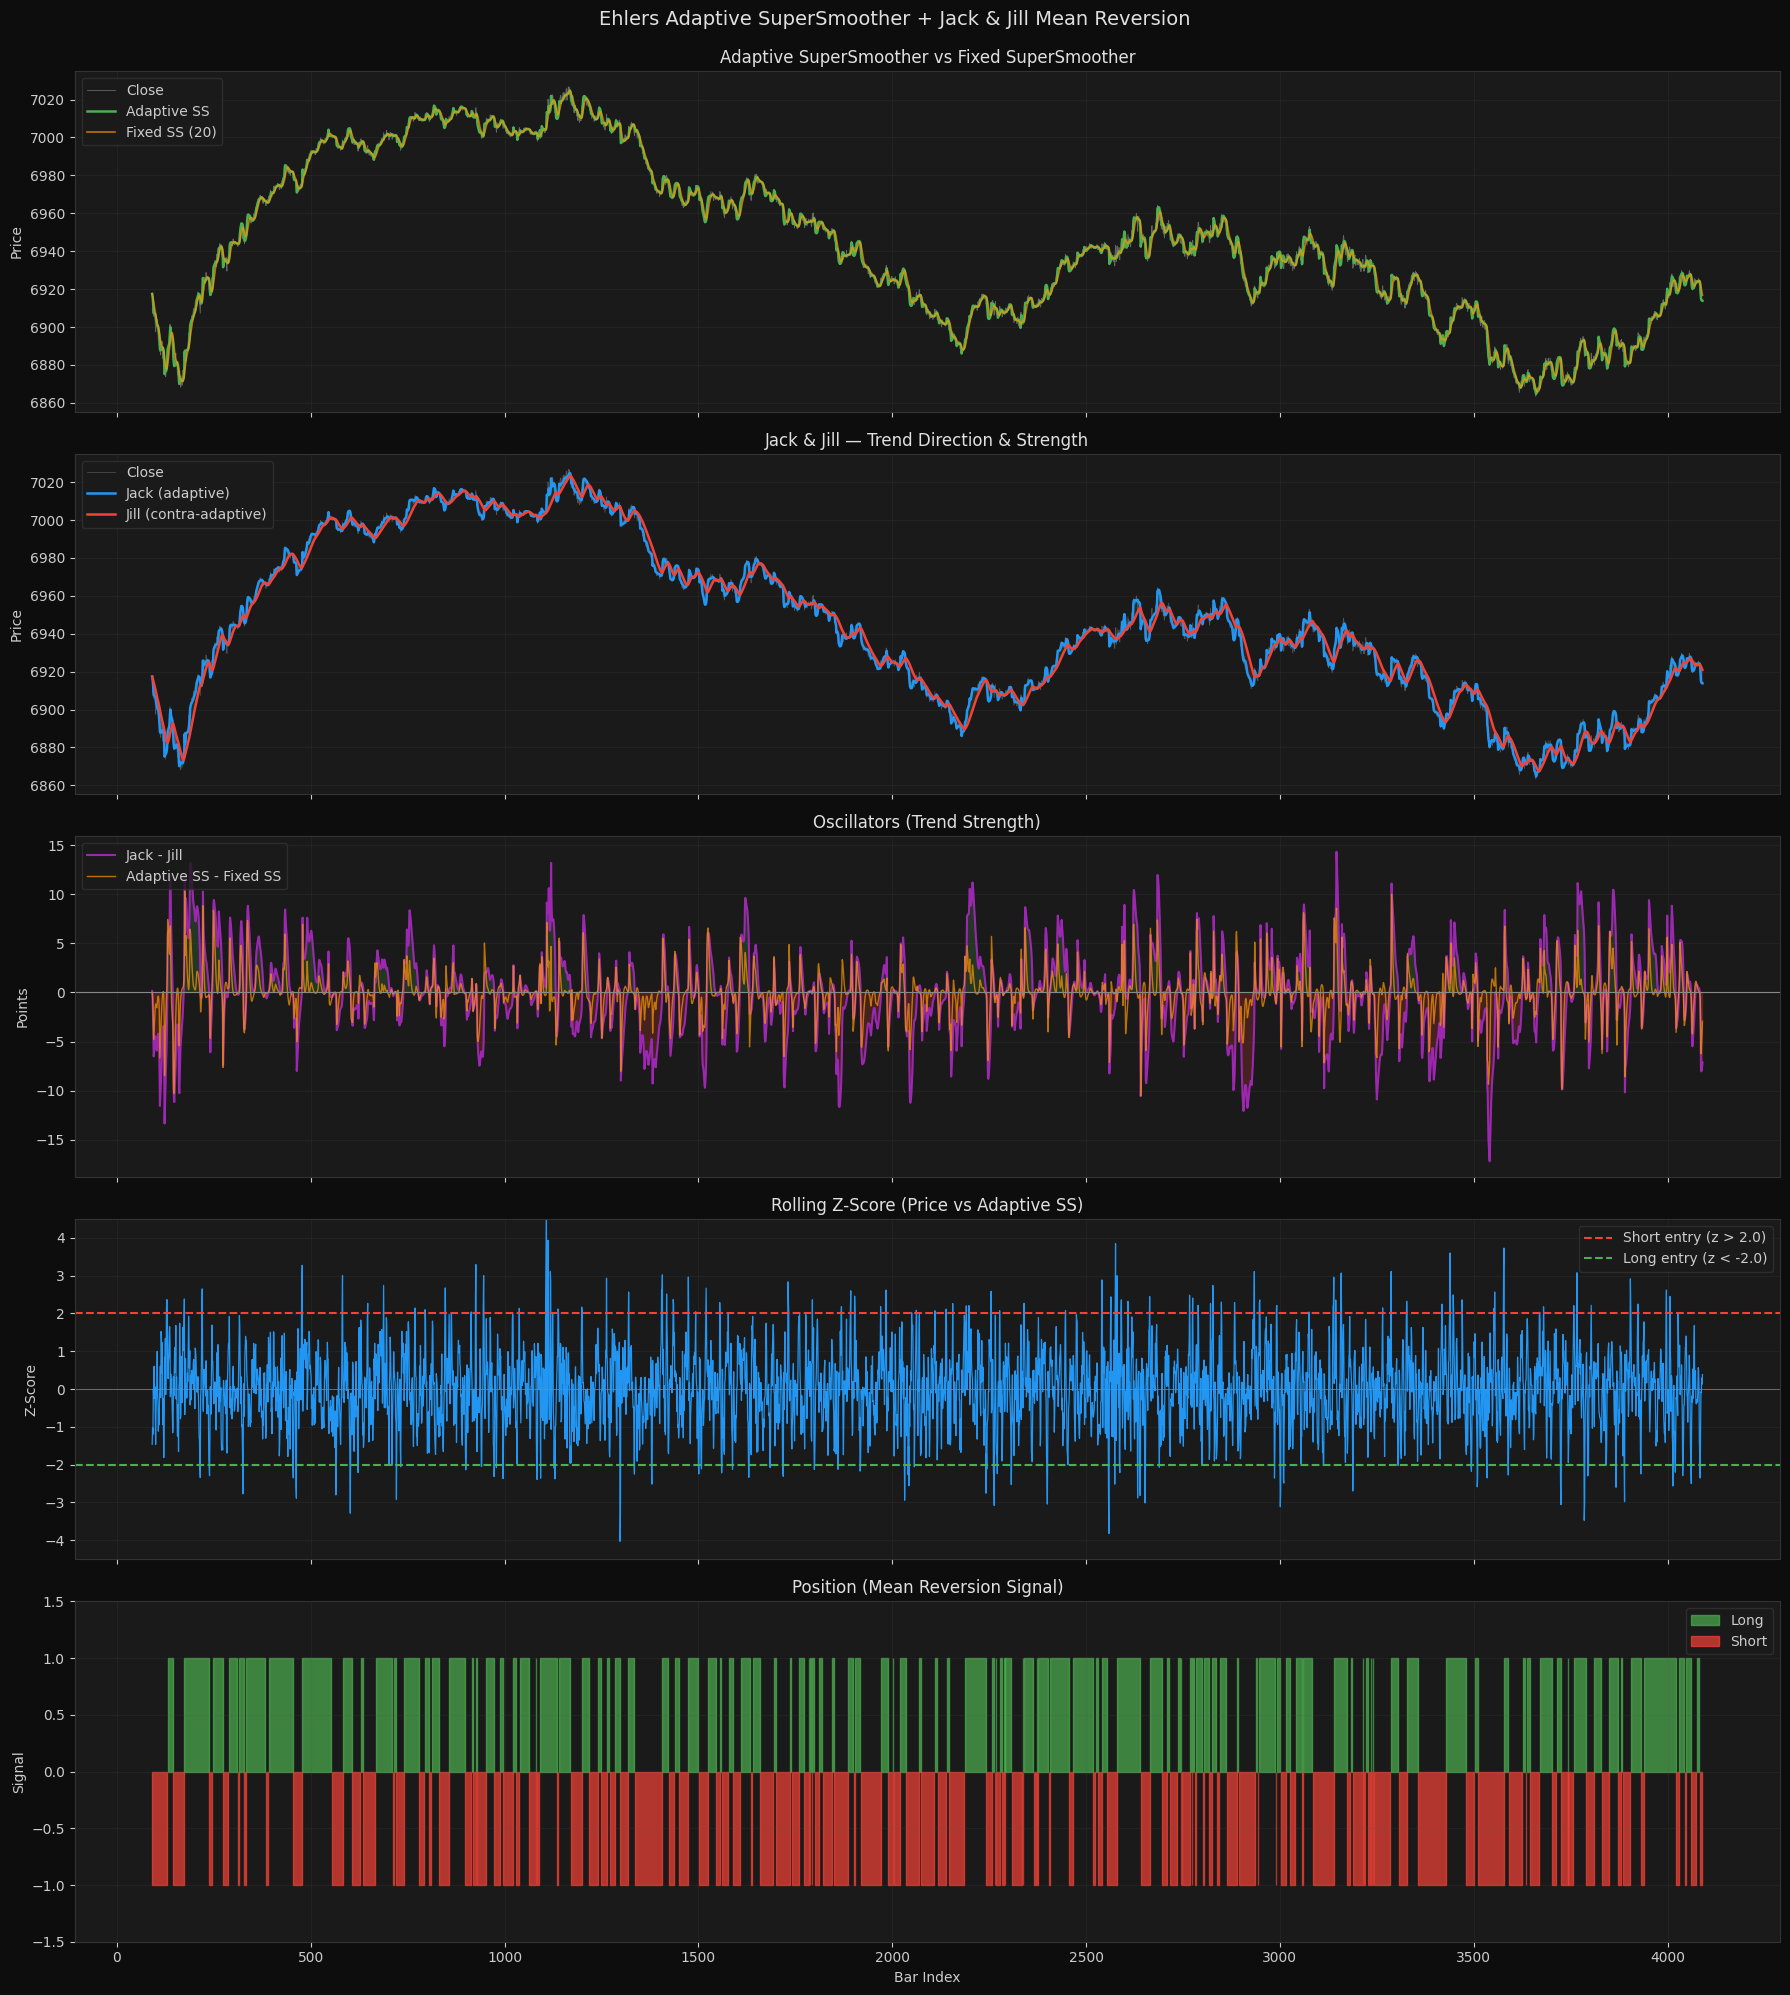

In [10]:
# =============================================================================
# Plot: Adaptive SuperSmoother, Jack & Jill, Oscillators, Signal
# =============================================================================
fig, axes = plt.subplots(5, 1, figsize=(18, 20), sharex=True)
fig.patch.set_facecolor('#0d0d0d')
fig.suptitle('Ehlers Adaptive SuperSmoother + Jack & Jill Mean Reversion',
             color='#e0e0e0', fontsize=14, y=0.995)

for ax in axes:
    ax.set_facecolor('#1a1a1a')
    ax.tick_params(colors='#ccc')
    ax.xaxis.label.set_color('#ccc')
    ax.yaxis.label.set_color('#ccc')
    ax.title.set_color('#e0e0e0')
    for spine in ax.spines.values():
        spine.set_color('#333')
    ax.grid(True, alpha=0.15, color='#555')

view_start = warmup
view_end = min(warmup + 4000, n_bars)
x = np.arange(view_start, view_end)

# Panel 1: Price + Adaptive SS + Fixed SS
ax = axes[0]
ax.plot(x, close[view_start:view_end], color='#666', linewidth=0.6, label='Close')
ax.plot(x, adaptive_ss[view_start:view_end], color='#4CAF50', linewidth=1.8, label='Adaptive SS')
ax.plot(x, fixed_ss[view_start:view_end], color='#FF9800', linewidth=1.2, alpha=0.7, label=f'Fixed SS ({PERIOD0})')
ax.set_title('Adaptive SuperSmoother vs Fixed SuperSmoother')
ax.set_ylabel('Price')
ax.legend(facecolor='#1a1a1a', edgecolor='#333', labelcolor='#ccc', loc='upper left')

# Panel 2: Jack & Jill overlay on price
ax = axes[1]
ax.plot(x, close[view_start:view_end], color='#555', linewidth=0.5, label='Close')
ax.plot(x, jack[view_start:view_end], color='#2196F3', linewidth=1.8, label='Jack (adaptive)')
ax.plot(x, jill[view_start:view_end], color='#f44336', linewidth=1.8, label='Jill (contra-adaptive)')
ax.fill_between(x, jack[view_start:view_end], jill[view_start:view_end],
                where=jack[view_start:view_end] > jill[view_start:view_end],
                color='#4CAF50', alpha=0.15)
ax.fill_between(x, jack[view_start:view_end], jill[view_start:view_end],
                where=jack[view_start:view_end] < jill[view_start:view_end],
                color='#f44336', alpha=0.15)
ax.set_title('Jack & Jill — Trend Direction & Strength')
ax.set_ylabel('Price')
ax.legend(facecolor='#1a1a1a', edgecolor='#333', labelcolor='#ccc', loc='upper left')

# Panel 3: Jack-Jill oscillator + Adaptive SS oscillator
ax = axes[2]
ax.plot(x, jj_oscillator[view_start:view_end], color='#9C27B0', linewidth=1.5, label='Jack - Jill')
ax.plot(x, ss_oscillator[view_start:view_end], color='#FF9800', linewidth=1, alpha=0.7, label='Adaptive SS - Fixed SS')
ax.axhline(0, color='#888', linewidth=0.8)
ax.fill_between(x, jj_oscillator[view_start:view_end], 0,
                where=jj_oscillator[view_start:view_end] > 0, color='#4CAF50', alpha=0.2)
ax.fill_between(x, jj_oscillator[view_start:view_end], 0,
                where=jj_oscillator[view_start:view_end] < 0, color='#f44336', alpha=0.2)
ax.set_title('Oscillators (Trend Strength)')
ax.set_ylabel('Points')
ax.legend(facecolor='#1a1a1a', edgecolor='#333', labelcolor='#ccc', loc='upper left')

# Panel 4: Z-Score with entry thresholds
ax = axes[3]
ax.plot(x, zscore[view_start:view_end], color='#2196F3', linewidth=0.9)
ax.axhline(ENTRY_Z, color='#f44336', linestyle='--', linewidth=1.5, label=f'Short entry (z > {ENTRY_Z})')
ax.axhline(-ENTRY_Z, color='#4CAF50', linestyle='--', linewidth=1.5, label=f'Long entry (z < -{ENTRY_Z})')
ax.axhline(0, color='#888', linewidth=0.5)
ax.set_title('Rolling Z-Score (Price vs Adaptive SS)')
ax.set_ylabel('Z-Score')
ax.set_ylim(-4.5, 4.5)
ax.legend(facecolor='#1a1a1a', edgecolor='#333', labelcolor='#ccc', loc='upper right')

# Panel 5: Position
ax = axes[4]
ax.fill_between(x, signal[view_start:view_end], 0,
                where=signal[view_start:view_end] > 0, color='#4CAF50', alpha=0.7, label='Long')
ax.fill_between(x, signal[view_start:view_end], 0,
                where=signal[view_start:view_end] < 0, color='#f44336', alpha=0.7, label='Short')
ax.set_title('Position (Mean Reversion Signal)')
ax.set_ylabel('Signal')
ax.set_xlabel('Bar Index')
ax.set_ylim(-1.5, 1.5)
ax.legend(facecolor='#1a1a1a', edgecolor='#333', labelcolor='#ccc')

plt.tight_layout()
plt.show()

In [11]:
bt = Backtester(
    ohlc=ohlc,
    indicies=indices,
    signal=signal,
    timeframe=timeframe,
    tick_value=tick_value,
    contract_multiplier=contract_multiplier,
    initial_equity=initial_equity,
    slippage_ticks=1.0,
    commission=3.50,
)
bt.full_backtest()
print(bt)


        Backtest Results from 2026-02-01 23:00:07.009440-06:00 to 2026-03-02 07:28:53.006560-06:00 (28 days 08:28:45.997120)
        Equity:     $100,000.00 -> $74,710.00
        Buy & Hold: $100,000.00 -> $92,375.00
        Buy & Hold Return (%): -7.62%
        Strategy Return (%):   -25.29%

        Total Trades:     1265.00
        Win Rate:         34.23%
        95% CI:           31.67% - 36.89%
        Avg. Win:         $379.84
        Avg. Loss:        $-228.08
        Ratio Win/Loss:   1.67
        Expected Value:   $-19.99

        Largest Win:      $3,171.50
        Largest Loss:     $-1,178.50
        Max Consec. Wins: 6
        Max Consec. Loss: 15

        Max Drawdown from 2026-02-02 18:22:13.004000-06:00 to 2026-02-13 14:31:15.000800-06:00 (10 days 20:09:01.996800)
        Max Drawdown:     $-37,827.00
        Max Drawdown (%): -36.48%

        Slippage:   1.0 ticks
        Commission: $3.50
        Contract Multiplier: $50.00
        Transaction Costs:   $20,240.00

  

In [12]:
from Engine.Report import generate_report
generate_report(bt, 'backtest_report.html', open_browser=True)

Report saved: /Users/newuser/Desktop/Random Coding Crap/Futures/RugbeatunosBacktestingSuite/backtest_report.html


'/Users/newuser/Desktop/Random Coding Crap/Futures/RugbeatunosBacktestingSuite/backtest_report.html'